# HS4002 Week 11

## Panel Data Models

Panel data follows the **same units** (people, players, countries) across multiple time points, allowing us to control for unobserved unit-level heterogeneity.

In Python, the `linearmodels` library provides panel regression — equivalent to R's `plm` package.

We'll use NBA player data (2013–2017) to ask: **how does a player's age affect their scoring performance?**

In [9]:
%pip install linearmodels

In [10]:
# !pip install pandas numpy plotnine linearmodels stargazer

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS

## Setup: Load and Prepare the NBA Dataset

In [11]:
# Data source: https://www.kaggle.com/datasets/drgilermo/nba-players-stats
# NBA player statistics 1950-2017 from basketball-reference.com
raw_df = pd.read_csv("https://raw.githubusercontent.com/xiangyum/hs4002labs_2026/main/week11/bball.csv").iloc[:, 1:]

df = (
	raw_df[raw_df["Year"] >= 2013]
	.groupby(["Player", "Year"])
	.agg(
		games_played    = ("G",    "sum"),
		games_started   = ("GS",   "sum"),
		minutes_played  = ("MP",   "sum"),
		age             = ("Age",  "mean"),
		personal_fouls  = ("PF",   "sum"),
		points          = ("PTS",  "sum"),
		true_shooting   = ("TS%",  "mean"),
		assists         = ("AST",  "sum"),
		steals          = ("STL",  "sum"),
		blocks          = ("BLK",  "sum"),
		fga             = ("FGA",  "sum"),
		fg              = ("FG",   "sum"),
		threeP          = ("3P",   "sum"),
		threePA         = ("3PA",  "sum"),
		twoP            = ("2P",   "sum"),
		twoPA           = ("2PA",  "sum"),
		ft              = ("FT",   "sum"),
		fta             = ("FTA",  "sum"),
		def_rb          = ("DRB",  "sum"),
		off_rb          = ("ORB",  "sum"),
	)
	.assign(ppg=lambda x: x["points"] / x["games_played"])
	.reset_index()
)
print(df.shape)
df.head()

(2403, 23)


,Player,Year,games_played,games_started,minutes_played,age,personal_fouls,points,true_shooting,assists,...,fg,threeP,threePA,twoP,twoPA,ft,fta,def_rb,off_rb,ppg
0,A.J. Hammons,2017.0,22.0,0.0,163.0,24.0,21.0,48.0,0.472000,4.0,...,17.0,5.0,10.0,12.0,32.0,9.0,20.0,28.0,8.0,2.181818
1,A.J. Price,2013.0,57.0,22.0,1278.0,26.0,73.0,441.0,0.501000,205.0,...,161.0,70.0,200.0,91.0,213.0,49.0,62.0,94.0,20.0,7.736842
2,A.J. Price,2014.0,28.0,0.0,99.0,27.0,5.0,44.0,0.469000,13.0,...,19.0,6.0,22.0,13.0,24.0,0.0,2.0,9.0,1.0,1.571429
3,A.J. Price,2015.0,52.0,0.0,648.0,28.0,30.0,266.0,0.376750,92.0,...,102.0,30.0,114.0,72.0,160.0,32.0,48.0,52.0,12.0,5.115385
4,Aaron Brooks,2013.0,106.0,40.0,1994.0,28.0,188.0,752.0,0.500667,228.0,...,286.0,100.0,268.0,186.0,364.0,80.0,104.0,134.0,26.0,7.094340


## Setting up the Panel Index

`linearmodels` requires a **MultiIndex** of (entity, time). Equivalent to the `index=c('Player','Year')` argument in R's `plm()`.

In [12]:
# Set the panel index — required by linearmodels
df_panel = df.set_index(['Player', 'Year'])

# A Tutorial for Panel Models

## Pooled OLS

Equivalent to a regular `lm()` in R — ignores the panel structure.

In [13]:
pool_model = PooledOLS.from_formula('ppg ~ age + I(age**2)', data=df_panel)
pool_result = pool_model.fit()
print(pool_result.summary)

                          PooledOLS Estimation Summary                          
Dep. Variable:                    ppg   R-squared:                        0.6757
Estimator:                  PooledOLS   R-squared (Between):              0.6103
No. Observations:                2403   R-squared (Within):               0.0318
Date:                Fri, Nov 20 2026   R-squared (Overall):              0.6757
Time:                        09:44:50   Log-likelihood                   -7587.5
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      2501.2
Entities:                         817   P-value                           0.0000
Avg Obs:                       2.9412   Distribution:                  F(2,2401)
Min Obs:                       1.0000                                           
Max Obs:                       5.0000   F-statistic (robust):             2501.2
                            

## Fixed Effects (Within) Model

Adds `EntityEffects` to control for time-invariant player characteristics. Equivalent to `plm(..., model='within')` in R.

In [14]:
fe_model = PanelOLS.from_formula('ppg ~ age + I(age**2) + EntityEffects', data=df_panel)
fe_result = fe_model.fit()
print(fe_result.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                    ppg   R-squared:                        0.1774
Estimator:                   PanelOLS   R-squared (Between):             -66.812
No. Observations:                2403   R-squared (Within):               0.1774
Date:                Fri, Nov 20 2026   R-squared (Overall):             -43.473
Time:                        09:44:50   Log-likelihood                   -5167.4
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      170.80
Entities:                         817   P-value                           0.0000
Avg Obs:                       2.9412   Distribution:                  F(2,1584)
Min Obs:                       1.0000                                           
Max Obs:                       5.0000   F-statistic (robust):             170.80
                            

Interpret the coefficients. How does the fixed-effects estimate differ from the pooled OLS estimate?

## Random Effects Model

Equivalent to `plm(..., model='random')` in R.

In [15]:
re_model = RandomEffects.from_formula('ppg ~ age + I(age**2)', data=df_panel)
re_result = re_model.fit()
print(re_result.summary)

                        RandomEffects Estimation Summary                        
Dep. Variable:                    ppg   R-squared:                        0.3804
Estimator:              RandomEffects   R-squared (Between):              0.6371
No. Observations:                2403   R-squared (Within):               0.0412
Date:                Fri, Nov 20 2026   R-squared (Overall):              0.6573
Time:                        09:44:50   Log-likelihood                   -5810.5
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      737.02
Entities:                         817   P-value                           0.0000
Avg Obs:                       2.9412   Distribution:                  F(2,2401)
Min Obs:                       1.0000                                           
Max Obs:                       5.0000   F-statistic (robust):             737.02
                            

## Model Diagnostics

### Lagrange Multiplier Test

Tests whether individual effects are present (i.e., whether FE/RE is needed over pooled OLS). Equivalent to R's `plmtest(fe_model, effect='individual')`.

In [16]:
# Breusch-Pagan LM test for random effects
# Under H0 (no individual effects), we prefer pooled OLS.
# Equivalent to R's plmtest(..., effect='individual', type='bp').
from scipy.stats import chi2

resid = pool_result.resids
e_i   = resid.groupby(level=0).sum()
ssr   = float((resid ** 2).sum())
A1    = float((e_i ** 2).sum()) / ssr - 1
T_i   = resid.groupby(level=0).size()
n_obs = resid.shape[0]
lm_stat = (n_obs ** 2) / (2 * (float((T_i ** 2).sum()) - n_obs)) * A1 ** 2
lm_pval = chi2.sf(lm_stat, df=1)

print('LM test for individual effects:')
print(f'LM statistic = {lm_stat:.4f}')
print('df = 1')
print(f'p-value = {lm_pval:.4f}')

LM test for individual effects:
LM statistic = 2381.2182
df = 1
p-value = 0.0000


### Hausman Test

Tests whether RE estimates are consistent (i.e., whether FE or RE is preferred). Under H0, RE is consistent and more efficient. Equivalent to R's `phtest(fe_model, re_model)`.

In [17]:
# Hausman test: compare FE and RE estimates
# Under H0 (RE consistent), the difference in coefficients should be small
from scipy.stats import chi2

common_params = fe_result.params.index.intersection(re_result.params.index)

beta_diff = fe_result.params[common_params] - re_result.params[common_params]
cov_diff  = (
	fe_result.cov.loc[common_params, common_params] -
	re_result.cov.loc[common_params, common_params]
)

h_stat = float(beta_diff.T @ np.linalg.inv(cov_diff.values) @ beta_diff)
p_val  = chi2.sf(h_stat, df=len(common_params))
print(f'Hausman statistic = {h_stat:.4f}')
print(f'df = {len(common_params)}')
print(f'p-value = {p_val:.4f}')
print('Prefer FE over RE:', p_val < 0.05)

Hausman statistic = 285.0094
df = 2
p-value = 0.0000
Prefer FE over RE: True


## Comparing the Models

As in earlier weeks, `stargazer` collects the fitted models into one regression table. Reading pooled OLS, fixed effects, and random effects side by side is easier than scrolling through three summaries. Equivalent to R's `stargazer(lm1, fe_glm1, re_glm1)`.

In [19]:
%pip install stargazer

In [20]:
from stargazer.stargazer import Stargazer

sg = Stargazer([pool_result, fe_result, re_result])
sg.title('Points per Game and Age')

# Label the models and variables readably, rather than by raw column name
sg.dependent_variable_name('Points per game')
sg.custom_columns(['Pooled OLS', 'Fixed Effects', 'Random Effects'], [1, 1, 1])
sg.covariate_order(['age', 'I(age ** 2)'])
sg.rename_covariates({
	'age':         'Age',
	'I(age ** 2)': 'Age-squared',
})

# Ending the cell on the object itself renders the table in the notebook
sg

# Independent Analysis: Has Sports Science Extended Career Peaks?

Compare players from 2008–2012 with players from 2013–2017. Does age affect scoring differently across the two eras?

In [21]:
# (1) create two data sets, one for each era.

def build_era(raw, start, end):
    return (
        raw[(raw["Year"] >= start) & (raw["Year"] <= end)]
        .groupby(["Player", "Year"])
        .agg(
            games_played = ("G",   "sum"),
            points       = ("PTS", "sum"),
            age          = ("Age", "mean"),
        )
        .assign(ppg=lambda x: x["points"] / x["games_played"])
        .reset_index()
    )

df_early = build_era(raw_df, 2008, 2012)
df_late  = build_era(raw_df, 2013, 2017)

for name, d in [("2008-2012", df_early), ("2013-2017", df_late)]:
    print(f"{name}: {d.shape[0]} player-seasons, {d['Player'].nunique()} players, "
          f"mean age {d['age'].mean():.1f}, mean ppg {d['ppg'].mean():.2f}")

panel_early = df_early.set_index(["Player", "Year"])
panel_late  = df_late.set_index(["Player", "Year"])

2008-2012: 2266 player-seasons, 743 players, mean age 26.6, mean ppg 8.29
2013-2017: 2403 player-seasons, 817 players, mean age 26.5, mean ppg 8.19


In [22]:
# (2) fit models for each of the two data sets
# linearmodels doesn't add an intercept automatically, so "1 +" is added for pooled OLS and RE

def fit_panel_models(panel):
    pool = PooledOLS.from_formula("ppg ~ 1 + age + I(age**2)", data=panel).fit()
    fe   = PanelOLS.from_formula("ppg ~ age + I(age**2) + EntityEffects", data=panel).fit()
    re   = RandomEffects.from_formula("ppg ~ 1 + age + I(age**2)", data=panel).fit()
    return pool, fe, re

pool_early, fe_early, re_early = fit_panel_models(panel_early)
pool_late,  fe_late,  re_late  = fit_panel_models(panel_late)

print(fe_early.summary)
print(fe_late.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                    ppg   R-squared:                        0.2139
Estimator:                   PanelOLS   R-squared (Between):             -39.949
No. Observations:                2266   R-squared (Within):               0.2139
Date:                Fri, Nov 20 2026   R-squared (Overall):             -26.718
Time:                        09:46:49   Log-likelihood                   -4814.2
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      206.98
Entities:                         743   P-value                           0.0000
Avg Obs:                       3.0498   Distribution:                  F(2,1521)
Min Obs:                       1.0000                                           
Max Obs:                       5.0000   F-statistic (robust):             206.98
                            

In [23]:
# (3) run diagnostics, compare, and interpret for 2008-2012.

# --- helper functions (same LM and Hausman tests as the tutorial) ---
def lm_test(pool_result):
    resid = pool_result.resids
    e_i   = resid.groupby(level=0).sum()
    ssr   = float((resid ** 2).sum())
    A1    = float((e_i ** 2).sum()) / ssr - 1
    T_i   = resid.groupby(level=0).size()
    n_obs = resid.shape[0]
    stat  = (n_obs ** 2) / (2 * (float((T_i ** 2).sum()) - n_obs)) * A1 ** 2
    return stat, chi2.sf(stat, df=1)

def hausman_test(fe_result, re_result):
    common = fe_result.params.index.intersection(re_result.params.index)
    b_diff = fe_result.params[common] - re_result.params[common]
    v_diff = fe_result.cov.loc[common, common] - re_result.cov.loc[common, common]
    stat   = float(b_diff.T @ np.linalg.inv(v_diff.values) @ b_diff)
    return stat, chi2.sf(stat, df=len(common))

def peak_age(result):
    # ppg peaks where b1 + 2*b2*age = 0
    return -result.params["age"] / (2 * result.params["I(age ** 2)"])

def report(label, pool, fe, re):
    lm, lm_p = lm_test(pool)
    h,  h_p  = hausman_test(fe, re)
    print(f"===== {label} =====")
    print(f"LM test:      stat = {lm:.2f}, p = {lm_p:.4f}  -> individual effects present: {lm_p < 0.05}")
    print(f"Hausman test: stat = {h:.2f}, p = {h_p:.4f}  -> prefer FE over RE: {h_p < 0.05}")
    for name, r in [("Pooled OLS", pool), ("Fixed effects", fe), ("Random effects", re)]:
        print(f"{name:15s} age = {r.params['age']:.3f}, age^2 = {r.params['I(age ** 2)']:.4f}, "
              f"peak age = {peak_age(r):.1f}")

# --- 2008-2012 results ---
report("2008-2012", pool_early, fe_early, re_early)

sg_early = Stargazer([pool_early, fe_early, re_early])
sg_early.title("Points per Game and Age, 2008-2012")
sg_early.dependent_variable_name("Points per game")
sg_early.custom_columns(["Pooled OLS", "Fixed Effects", "Random Effects"], [1, 1, 1])
sg_early.covariate_order(["age", "I(age ** 2)"])
sg_early.rename_covariates({"age": "Age", "I(age ** 2)": "Age-squared"})
sg_early

===== 2008-2012 =====
LM test:      stat = 2494.25, p = 0.0000  -> individual effects present: True
Hausman test: stat = 151.69, p = 0.0000  -> prefer FE over RE: True
Pooled OLS      age = 1.857, age^2 = -0.0345, peak age = 26.9
Fixed effects   age = 5.094, age^2 = -0.1021, peak age = 24.9
Random effects  age = 3.831, age^2 = -0.0740, peak age = 25.9


In [26]:
# (4) run diagnostics, compare, and interpret for 2013-2017.
report("2013-2017", pool_late, fe_late, re_late)

from linearmodels.panel import compare
compare({"Pooled OLS": pool_late, "Fixed Effects": fe_late, "Random Effects": re_late}, stars=True)

===== 2013-2017 =====
LM test:      stat = 2429.25, p = 0.0000  -> individual effects present: True
Hausman test: stat = 131.39, p = 0.0000  -> prefer FE over RE: True
Pooled OLS      age = 1.859, age^2 = -0.0329, peak age = 28.2
Fixed effects   age = 5.745, age^2 = -0.1078, peak age = 26.6
Random effects  age = 3.857, age^2 = -0.0703, peak age = 27.4


,Pooled OLS,Fixed Effects,Random Effects
Dep. Variable,ppg,ppg,ppg
Estimator,PooledOLS,PanelOLS,RandomEffects
No. Observations,2403,2403,2403
Cov. Est.,Unadjusted,Unadjusted,Unadjusted
R-squared,0.0169,0.1774,-0.0029
R-Squared (Within),0.0852,0.1774,0.1505
R-Squared (Between),-0.0957,-66.812,-0.0837
R-Squared (Overall),0.0169,-43.473,-0.0531
F-statistic,20.673,170.80,107.01
P-value (F-stat),0.0000,0.0000,0.0000


          2008-2012  2013-2017
age           5.094      5.745
age^2        -0.102     -0.108
peak age     24.948     26.641 

                          PanelOLS Estimation Summary                           
Dep. Variable:                    ppg   R-squared:                        0.1951
Estimator:                   PanelOLS   R-squared (Between):             -53.509
No. Observations:                4669   R-squared (Within):               0.1951
Date:                Fri, Nov 20 2026   R-squared (Overall):             -35.192
Time:                        09:48:38   Log-likelihood                   -9982.4
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      188.13
Entities:                        1560   P-value                           0.0000
Avg Obs:                       2.9929   Distribution:                  F(4,3105)
Min Obs:                       1.0000                           

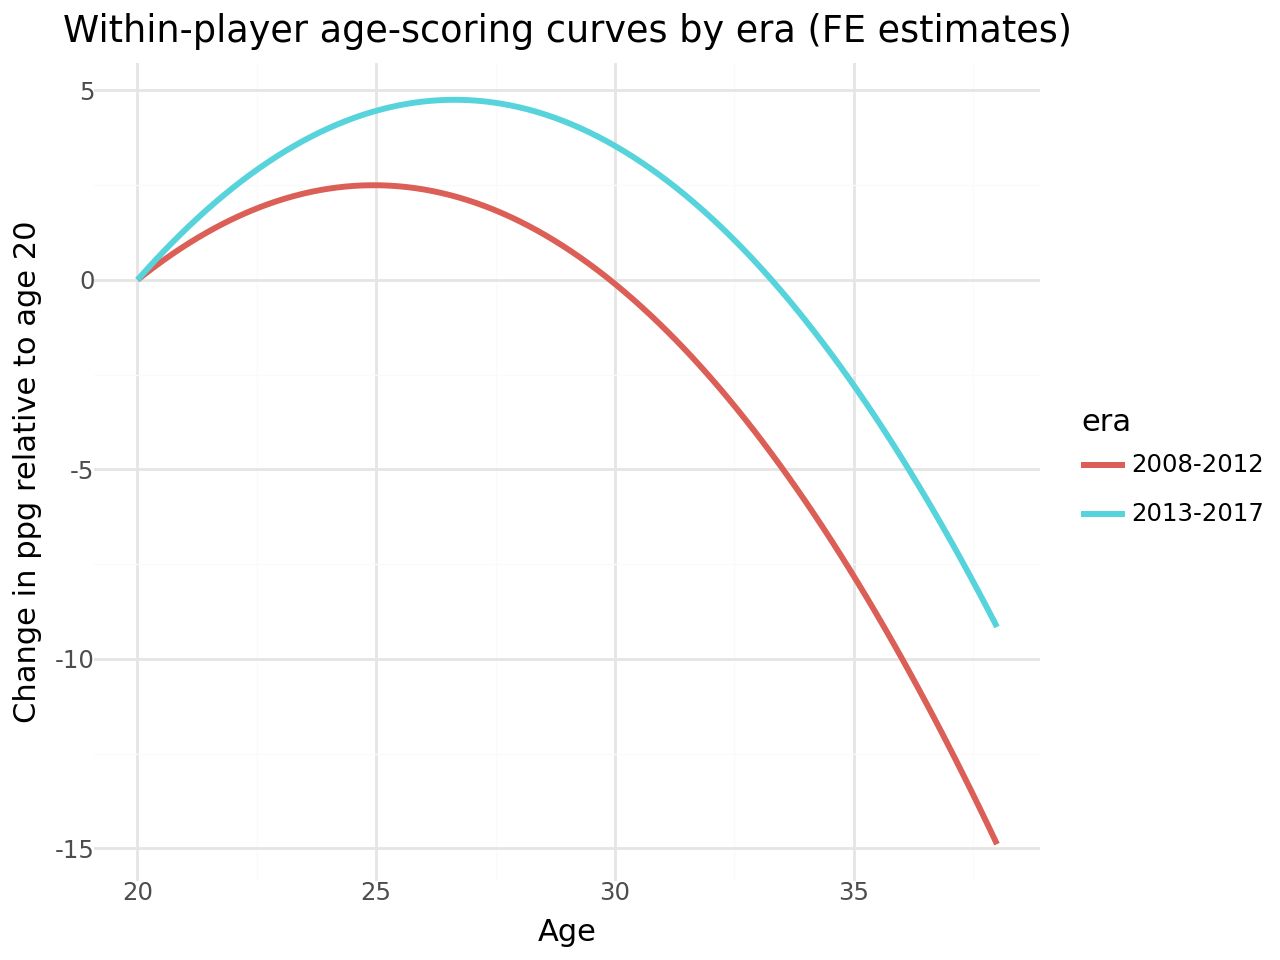

In [27]:
# (5) what differences do you find in the age-scoring relationship across the two eras?

# Side-by-side FE comparison
compare = pd.DataFrame({
    era: {"age": r.params["age"], "age^2": r.params["I(age ** 2)"], "peak age": peak_age(r)}
    for era, r in [("2008-2012", fe_early), ("2013-2017", fe_late)]
}).round(3)
print(compare, "\n")

# Is the difference significant? Pool both eras and let the age curve differ by era.
# Entity = player x era, so each player gets a separate baseline per era.
df_both = pd.concat([df_early.assign(late=0), df_late.assign(late=1)])
df_both["player_era"] = df_both["Player"] + "_" + df_both["late"].astype(str)
panel_both = df_both.set_index(["player_era", "Year"])

fe_inter = PanelOLS.from_formula(
    "ppg ~ age + I(age**2) + age:late + I(age**2):late + EntityEffects", data=panel_both
).fit(cov_type="clustered", cluster_entity=True)
print(fe_inter.summary)

# Joint Wald test: are the two era interaction terms together zero?
inter_terms = [t for t in fe_inter.params.index if "late" in t]
b_int = fe_inter.params[inter_terms]
V_int = fe_inter.cov.loc[inter_terms, inter_terms]
wald  = float(b_int.T @ np.linalg.inv(V_int.values) @ b_int)
print(f"Joint Wald test: chi2 = {wald:.2f}, df = {len(inter_terms)}, "
      f"p = {chi2.sf(wald, df=len(inter_terms)):.4f}")

# Plot the FE age curves for both eras (each measured relative to age 20)
ages = np.linspace(20, 38, 100)
curves = pd.concat([
    pd.DataFrame({"age": ages,
                  "ppg_change": r.params["age"] * (ages - 20) + r.params["I(age ** 2)"] * (ages**2 - 20**2),
                  "era": era})
    for era, r in [("2008-2012", fe_early), ("2013-2017", fe_late)]
])
(ggplot(curves, aes("age", "ppg_change", color="era"))
 + geom_line(size=1.2)
 + labs(x="Age", y="Change in ppg relative to age 20",
        title="Within-player age-scoring curves by era (FE estimates)")
 + theme_minimal())